# Modelos de churn y segmentación de clientes

**Equipo:** Modelos · **Dataset:** `telco_churn_clean.csv`

Este notebook compara dos clasificadores para predecir `Churn` y crea segmentos con K-Means. Se conserva intacto el CSV entregado por Limpieza y EDA. La preparación supervisada vive dentro de un `Pipeline` para que el escalado y la codificación se ajusten solo con los datos de entrenamiento.

**Evaluación:** split estratificado 80/20, semilla fija; mostramos el baseline con umbral 0.50 y ajustamos un umbral para cada modelo solo con validación cruzada del train. Reportamos precision, recall, F1 y matriz de confusión para `Yes`. F1 de la clase `Yes` es el criterio principal porque equilibra precision y recall; precision y recall se reportan para hacer visible el intercambio.

> Las relaciones y probabilidades describen este dataset; no demuestran causas ni garantizan el comportamiento futuro.

## 1. Librerías y rutas

Si falta una librería en el entorno de VS Code, instálala en el entorno virtual del proyecto: `python3 -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter`. En Mac, selecciona ese entorno como kernel del notebook.

In [1]:
from pathlib import Path
import warnings
import sys
import json
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score, recall_score, silhouette_score,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
NOTEBOOK_CWD = Path.cwd().resolve()
REPO_ROOT = next((root for root in [NOTEBOOK_CWD, *NOTEBOOK_CWD.parents] if (root / ".git").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("No encontré la raíz del repositorio Git. Abre el notebook desde una copia del proyecto.")

PROJECT_DIR = REPO_ROOT
sys.path.insert(0, str(PROJECT_DIR))
from src.modeling.feature_engineering import build_model_features
DATA_PATH = PROJECT_DIR / "data" / "processed" / "telco_churn_clean.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"No encontré el CSV limpio en {DATA_PATH}. Actualiza la rama con los cambios del equipo de Limpieza y EDA."
    )

OUTPUT_DIR = PROJECT_DIR / "data" / "output"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"Datos: {DATA_PATH}")
print(f"Salidas: {OUTPUT_DIR}")


Datos: /Users/teudysperez/Talendig - Data Science, Python and Machine Learning/customer-churn-analysis/data/processed/telco_churn_clean.csv
Salidas: /Users/teudysperez/Talendig - Data Science, Python and Machine Learning/customer-churn-analysis/data/output


## 2. Cargar y validar datos

`customerID` identifica al cliente y no es una señal predictiva. `Churn` es el objetivo; la convertimos a 1 para `Yes` y 0 para `No`. Las filas duplicadas por identificador deben revisarse antes de entrenar.

In [2]:
df = pd.read_csv(DATA_PATH)

assert len(df) == 7043, f"Se esperaban 7043 filas; hay {len(df)}"
assert "customerID" in df.columns and "Churn" in df.columns
assert df["customerID"].is_unique, "customerID tiene duplicados"
assert df.isna().sum().sum() == 0, "El CSV contiene nulos"
assert set(df["Churn"].unique()) == {"Yes", "No"}

y = (df["Churn"] == "Yes").astype(int)
MODEL_INPUT_DROP_COLUMNS = ["PhoneService", "MultipleLines", "TotalCharges"]
X = df.drop(columns=["customerID", "Churn", *MODEL_INPUT_DROP_COLUMNS])
print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas".replace(",", "."))
print(f"Tasa de churn: {y.mean():.1%}")
print(f"Variables predictoras base para entrenamiento: {X.shape[1]}")
churn_summary = (
    df["Churn"]
    .value_counts()
    .rename_axis("Churn")
    .to_frame("Clientes")
    .assign(Porcentaje=lambda table: table["Clientes"] / len(df))
)
churn_summary.style.format({"Clientes": "{:,.0f}", "Porcentaje": "{:.1%}"})


Dataset: 7.043 filas × 21 columnas
Tasa de churn: 26.5%
Variables predictoras base para entrenamiento: 16


,Clientes,Porcentaje
Churn,,
No,"5,174",73.5%
Yes,"1,869",26.5%


## 3. Separación train/test y preprocesamiento

El conjunto de prueba se reserva hasta la evaluación. One-hot encoding y escalado se ajustan dentro de cada pipeline con `X_train` solamente. Las categorías nuevas que aparezcan en test se ignoran de forma segura.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_ENGINEERED = build_model_features(X)
numeric_features = X_ENGINEERED.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_ENGINEERED.select_dtypes(exclude=["number"]).columns.tolist()
print(f"Variables derivadas para el clasificador: {X_ENGINEERED.shape[1]}")

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print(f"Train: {len(X_train):,} filas × {X_train.shape[1]} columnas".replace(",", "."))
print(f"Test:  {len(X_test):,} filas × {X_test.shape[1]} columnas".replace(",", "."))
split_churn_rate = pd.DataFrame(
    {"Proporción de churn": [y_train.mean(), y_test.mean()]},
    index=["Train", "Test"],
)
display(split_churn_rate.style.format("{:.1%}"))


Variables derivadas para el clasificador: 12
Train: 5.634 filas × 16 columnas
Test:  1.409 filas × 16 columnas


,Proporción de churn
Train,26.5%
Test,26.5%


## 4. Entrenar y comparar clasificadores

Comparamos Regresión Logística como referencia interpretable y Random Forest como modelo no lineal, usando las mismas 12 variables derivadas. Los pasos de imputación, escalado y codificación se ajustan dentro del pipeline. Random Forest usa pesos balanceados para compensar el desbalance de churn. Luego elegimos el modelo según F1 medio en cinco divisiones; si quedan a menos de 0.005, favorecemos mayor recall.


In [4]:
models = {
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

fitted_models = {}
rows = []
for name, estimator in models.items():
    pipeline = Pipeline([
        ("feature_engineering", FunctionTransformer(build_model_features, validate=False)),
        ("preprocess", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    rows.append({
        "modelo": name,
        "precision_yes": precision_score(y_test, pred, zero_division=0),
        "recall_yes": recall_score(y_test, pred, zero_division=0),
        "f1_yes": f1_score(y_test, pred, zero_division=0),
    })

metrics = pd.DataFrame(rows).set_index("modelo").sort_values("f1_yes", ascending=False)
metrics_display = metrics.rename(columns={
    "precision_yes": "Precision (Yes)",
    "recall_yes": "Recall (Yes)",
    "f1_yes": "F1 (Yes)",
})
metrics_display.style.format("{:.3f}").set_caption("Test con umbral 0.50")


,Precision (Yes),Recall (Yes),F1 (Yes)
modelo,,,
Random Forest,0.542,0.727,0.621
Regresión logística,0.628,0.524,0.571


In [5]:
for name, pipeline in fitted_models.items():
    pred = pipeline.predict(X_test)
    matrix = confusion_matrix(y_test, pred, labels=[0, 1])
    matrix_display = pd.DataFrame(
        matrix,
        index=pd.Index(["Real: No", "Real: Yes"], name="Clase real"),
        columns=pd.Index(["Predicho: No", "Predicho: Yes"], name="Predicción"),
    )
    display(matrix_display.style.format("{:,.0f}").set_caption(f"{name} · umbral 0.50"))


Predicción,Predicho: No,Predicho: Yes
Clase real,,
Real: No,919,116
Real: Yes,178,196


Predicción,Predicho: No,Predicho: Yes
Clase real,,
Real: No,805,230
Real: Yes,102,272


In [6]:
# Cada modelo se ajusta con su propio umbral, elegido solo con OOF del train; test queda reservado.
threshold_grid = np.linspace(0.05, 0.80, 151)
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_thresholds = {}
tuned_rows = []
tuned_train_rows = []
tuned_test_predictions = {}

for name, pipeline in fitted_models.items():
    train_oof_proba = cross_val_predict(
        pipeline, X_train, y_train, cv=threshold_cv, method="predict_proba", n_jobs=1
    )[:, 1]
    threshold = max(
        threshold_grid,
        key=lambda value: f1_score(y_train, train_oof_proba >= value, zero_division=0),
    )
    tuned_thresholds[name] = float(threshold)
    oof_pred = (train_oof_proba >= threshold).astype(int)
    tuned_train_rows.append({
        "modelo": name, "threshold": threshold,
        "precision_yes": precision_score(y_train, oof_pred, zero_division=0),
        "recall_yes": recall_score(y_train, oof_pred, zero_division=0),
        "f1_yes": f1_score(y_train, oof_pred, zero_division=0),
    })
    test_proba = pipeline.predict_proba(X_test)[:, 1]
    test_pred = (test_proba >= threshold).astype(int)
    tuned_test_predictions[name] = test_pred
    tuned_rows.append({
        "modelo": name, "threshold": threshold,
        "precision_yes": precision_score(y_test, test_pred, zero_division=0),
        "recall_yes": recall_score(y_test, test_pred, zero_division=0),
        "f1_yes": f1_score(y_test, test_pred, zero_division=0),
    })

tuned_train_metrics = (
    pd.DataFrame(tuned_train_rows).set_index("modelo").sort_values("f1_yes", ascending=False)
)
tuned_metrics = pd.DataFrame(tuned_rows).set_index("modelo").sort_values("f1_yes", ascending=False)
metric_formats = {
    "threshold": "{:.3f}",
    "precision_yes": "{:.3f}",
    "recall_yes": "{:.3f}",
    "f1_yes": "{:.3f}",
}
metric_labels = {
    "threshold": "Umbral",
    "precision_yes": "Precision (Yes)",
    "recall_yes": "Recall (Yes)",
    "f1_yes": "F1 (Yes)",
}
metric_display_formats = {metric_labels[column]: fmt for column, fmt in metric_formats.items()}
print("Métricas OOF del train (ajuste del umbral):")
display(tuned_train_metrics.rename(columns=metric_labels).style.format(metric_display_formats).set_caption("Validación cruzada del train"))
print("Métricas del test reservado:")
tuned_metrics.rename(columns=metric_labels).style.format(metric_display_formats).set_caption("Evaluación final con umbral elegido en train")


Métricas OOF del train (ajuste del umbral):


,Umbral,Precision (Yes),Recall (Yes),F1 (Yes)
modelo,,,,
Regresión logística,0.325,0.559,0.739,0.637
Random Forest,0.465,0.530,0.761,0.625


Métricas del test reservado:


,Umbral,Precision (Yes),Recall (Yes),F1 (Yes)
modelo,,,,
Regresión logística,0.325,0.536,0.735,0.620
Random Forest,0.465,0.521,0.754,0.616


In [7]:
for name, pred in tuned_test_predictions.items():
    matrix = confusion_matrix(y_test, pred, labels=[0, 1])
    matrix_display = pd.DataFrame(
        matrix,
        index=pd.Index(["Real: No", "Real: Yes"], name="Clase real"),
        columns=pd.Index(["Predicho: No", "Predicho: Yes"], name="Predicción"),
    )
    caption = f"{name} · umbral {tuned_thresholds[name]:.2f}"
    display(matrix_display.style.format("{:,.0f}").set_caption(caption))


Predicción,Predicho: No,Predicho: Yes
Clase real,,
Real: No,797,238
Real: Yes,99,275


Predicción,Predicho: No,Predicho: Yes
Clase real,,
Real: No,776,259
Real: Yes,92,282


### Decisión del modelo supervisado

La clase positiva es `Churn = Yes`. F1 es el criterio principal; cuando los F1 quedan a menos de 0.005, revisamos recall.

**Reducción de variables.** El CSV limpio conserva sus 19 predictores. Primero agrupamos los seis servicios de internet en `SecuritySupportCount` y `StreamingServicesCount`, dando 15 variables derivadas. Después probamos eliminaciones individuales y combinadas con OOF de cinco folds, sin usar el holdout final para elegir. Seleccionamos 12 variables: quitamos `PhoneService`, `MultipleLines` y `TotalCharges`. El máximo F1 OOF de la búsqueda fue 0.628 con 14 variables; la opción de 12 quedó en 0.625 y su recall fue 0.761, frente a 0.738 de la base de 15. La diferencia de F1 queda dentro del margen 0.005 y el recall mejora.

En cinco particiones repetidas, Random Forest con 15 variables obtuvo F1 medio 0.629, recall 0.764 y precision 0.535. Con 12 variables obtuvo F1 0.626, recall 0.777 y precision 0.524. En el holdout reservado con umbral 0.460, la base tuvo F1 0.605 y recall 0.749; la versión de 12 tuvo F1 0.606 y recall 0.759.

**Elección del clasificador.** Con las 12 variables seleccionadas, Regresión Logística obtuvo F1 medio 0.633 (DE 0.017), recall 0.739 (0.004) y precision 0.553 (0.027). Random Forest obtuvo F1 0.626 (0.019), recall 0.777 (0.037) y precision 0.524 (0.013). La diferencia de F1 es 0.007, mayor que la tolerancia 0.005, por lo que elegimos **Regresión Logística** por F1 medio.

El umbral de despliegue es la mediana de los cinco umbrales OOF de Regresión Logística: `0.325`. En el holdout final separado (semilla 47), obtuvo precision 0.517, recall 0.735 y F1 0.607.

| Clase real / predicción | No | Yes |
|---|---:|---:|
| No | 778 | 257 |
| Yes | 99 | 275 |

El artefacto de clasificación para API recibe 12 variables listas para el modelo: diez variables directas más `SecuritySupportCount` y `StreamingServicesCount`. La página debe calcular esos conteos antes del POST a partir de las seis opciones de servicio. No se envían los seis indicadores originales, `customerID`, `Churn`, `PhoneService`, `MultipleLines` ni `TotalCharges`. Estas métricas son estimaciones sobre este dataset; la diferencia entre modelos es pequeña y la validación final debe repetirse con datos futuros.


## 5. Segmentación: variables, elección de k y algoritmo

Partimos de `tenure`, `MonthlyCharges` y `Contract`, y comparamos esa base con adiciones individuales, retiros de cada variable base y el conjunto completo de predictores. Elegimos agregar `InternetService`: produce grupos más equilibrados, una silueta ligeramente mayor y una separación más útil de las tasas de churn. `Churn` no se usa para formar los grupos; se cruza después para describirlos.


In [8]:
cluster_features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
cluster_prep = ColumnTransformer([
    ("num", StandardScaler(), ["tenure", "MonthlyCharges"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Contract", "InternetService"]),
], verbose_feature_names_out=False)

# El script evalúa variantes de variables y compara ambos algoritmos con k=2...8.
feature_comparison = pd.read_csv(OUTPUT_DIR / "clustering_feature_comparison.csv")
feature_table = feature_comparison[
    feature_comparison["candidate"].isin([
        "Base actual", "Base + InternetService", "Base + TotalCharges",
        "Base sin MonthlyCharges", "Todas las predictoras",
        "Base + ambos conteos de servicios",
        "Seleccion actual + SecuritySupportCount",
        "Seleccion actual + StreamingServicesCount",
        "Seleccion actual + ambos conteos",
    ])
][[
    "candidate", "n_input_features", "silhouette", "davies_bouldin",
    "calinski_harabasz", "min_cluster_pct", "max_cluster_churn_rate",
    "cluster_churn_rate_std",
]].rename(columns={
    "candidate": "Conjunto de variables",
    "n_input_features": "Variables",
    "silhouette": "Silueta",
    "davies_bouldin": "Davies–Bouldin",
    "calinski_harabasz": "Calinski–Harabasz",
    "min_cluster_pct": "Cluster menor (%)",
    "max_cluster_churn_rate": "Máxima tasa churn (%)",
    "cluster_churn_rate_std": "DE de churn por cluster",
})
feature_table.style.format({
    "Silueta": "{:.3f}",
    "Davies–Bouldin": "{:.3f}",
    "Calinski–Harabasz": "{:,.1f}",
    "Cluster menor (%)": "{:.1f}%",
    "Máxima tasa churn (%)": "{:.1%}",
    "DE de churn por cluster": "{:.3f}",
}).set_caption("Comparación de variables candidatas con K-Means, k=4")

cluster_comparison = pd.read_csv(OUTPUT_DIR / "clustering_model_comparison.csv")
k_results = cluster_comparison[cluster_comparison["algorithm"] == "K-Means"].copy()
gmm_results = cluster_comparison[cluster_comparison["algorithm"] == "Gaussian Mixture"].copy()
cluster_table = cluster_comparison.query("k in [4, 8]")[[
    "algorithm", "k", "inertia", "silhouette", "davies_bouldin",
    "calinski_harabasz", "min_cluster_pct",
]].rename(columns={
    "algorithm": "Algoritmo",
    "k": "k",
    "inertia": "Inercia",
    "silhouette": "Silueta",
    "davies_bouldin": "Davies–Bouldin",
    "calinski_harabasz": "Calinski–Harabasz",
    "min_cluster_pct": "Cluster menor (%)",
})
cluster_table.style.format({
    "Inercia": "{:,.1f}",
    "Silueta": "{:.3f}",
    "Davies–Bouldin": "{:.3f}",
    "Calinski–Harabasz": "{:,.1f}",
    "Cluster menor (%)": "{:.1f}%",
}).set_caption("Comparación de soluciones con k=4 y k=8, usando las cuatro variables elegidas")


,Algoritmo,k,Inercia,Silueta,Davies–Bouldin,Calinski–Harabasz,Cluster menor (%)
4,K-Means,4,"8,314.9",0.396,1.026,"4,087.5",21.7%
5,Gaussian Mixture,4,nan,0.369,1.058,"3,446.9",14.2%
12,K-Means,8,"3,929.7",0.461,0.897,"4,826.1",8.3%
13,Gaussian Mixture,8,nan,0.442,0.830,"3,493.5",5.2%


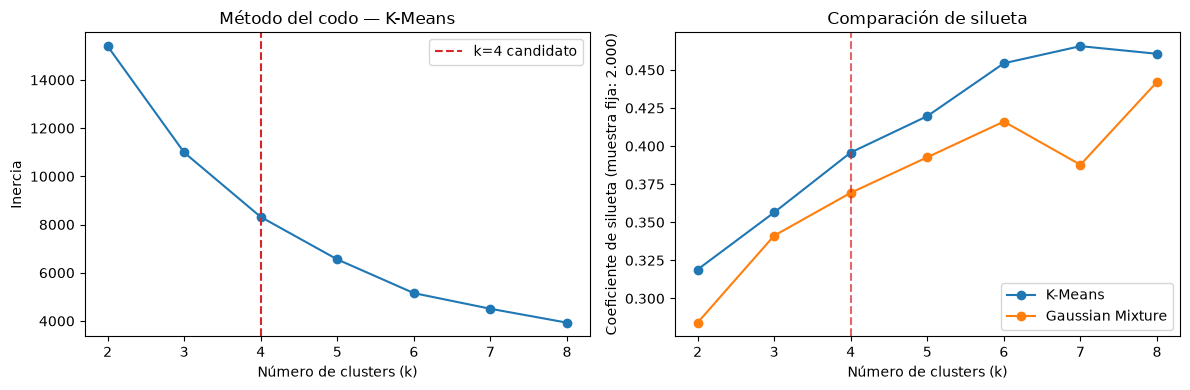

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].axvline(4, color="tab:red", linestyle="--", label="k=4 candidato")
axes[0].set(xlabel="Número de clusters (k)", ylabel="Inercia", title="Método del codo — K-Means")
axes[0].set_xticks(k_results["k"])
axes[0].legend()
axes[1].plot(k_results["k"], k_results["silhouette"], marker="o", label="K-Means")
axes[1].plot(gmm_results["k"], gmm_results["silhouette"], marker="o", label="Gaussian Mixture")
axes[1].axvline(4, color="tab:red", linestyle="--", alpha=0.7)
axes[1].set(xlabel="Número de clusters (k)", ylabel="Coeficiente de silueta (muestra fija: 2.000)", title="Comparación de silueta")
axes[1].set_xticks(k_results["k"])
axes[1].legend()
plt.tight_layout()
plt.show()

El barrido de variables con `k=4` incluyó cada predictor individualmente sobre la base, retiró cada una de las tres variables originales por turno y añadió un candidato con todos los predictores. También probó `SecuritySupportCount` y `StreamingServicesCount`, por separado y juntos, con y sin `InternetService`. `Base + InternetService` obtuvo silueta 0.396 (frente a 0.383), un grupo menor de 21.7% (frente a 16.3%) y una desviación estándar mayor entre tasas de churn de los clusters (0.223 frente a 0.198). Davies–Bouldin empeoró (1.026 frente a 0.967) y Calinski–Harabasz bajó (4,087.5 frente a 4,964.6), así que las métricas internas no apuntan todas a la misma opción.

`Base + TotalCharges` dio Davies–Bouldin y Calinski–Harabasz mejores que la base, pero `TotalCharges` acumula el efecto del tiempo y el cargo mensual, que ya están representados. Añadirlo puede contar dos veces dimensiones relacionadas. Quitar `MonthlyCharges` tuvo las mejores métricas internas (silueta 0.586), pero elimina el nivel de cargo, una dimensión útil para perfilar valor y diseñar acciones. Elegimos `InternetService` por su información de negocio diferenciada (sin internet, DSL o fibra), grupos más equilibrados y mayor diferenciación observada de churn; esta es una decisión de utilidad, no una victoria en todas las métricas. Los conteos de feature engineering no mejoraron la solución actual: al agregar ambos a la selección, la silueta bajó a 0.290, Davies–Bouldin subió a 1.273 y Calinski–Harabasz bajó a 3,272.3. Agregar solo `SecuritySupportCount` a las cuatro variables dio silueta 0.363; `StreamingServicesCount` dio 0.312. Los conteos resumen servicios para reducir variables en clasificación, pero aquí no mejoran la geometría de los grupos. 

Con las cuatro variables elegidas, la inercia baja de 10,989.7 en `k=3` a 8,314.9 en `k=4` y a 6,553.8 en `k=5`: la reducción se va aplanando y `k=4` deja cuatro grupos de al menos 21.7% cada uno. K-Means con `k=4` obtiene silueta 0.396, Davies–Bouldin 1.026 y Calinski–Harabasz 4,087.5. Con `k=8`, la silueta sube a 0.461 y Davies–Bouldin baja a 0.897, pero el cluster menor queda en 8.3%; mantenemos cuatro grupos por su tamaño y facilidad operativa.

Con `k=4`, Gaussian Mixture obtiene silueta 0.369, Davies–Bouldin 1.058 y Calinski–Harabasz 3,446.9. En esta representación, K-Means puntúa mejor en esas tres métricas. Seleccionamos **K-Means con `k=4`** por combinación de métricas, tamaños y posibilidad de describir cuatro perfiles.

La silueta se estima en la misma muestra aleatoria de 2,000 clientes. Las tasas de churn se calculan solo después de asignar los clusters y no intervienen en el ajuste ni en las métricas internas.


In [10]:
K_SELECTED = 4  # Cuatro perfiles equilibrados y operativamente manejables
cluster_pipeline = Pipeline([
    ("preprocess", cluster_prep),
    ("model", KMeans(n_clusters=K_SELECTED, random_state=RANDOM_STATE, n_init=20)),
])
# El pipeline recibe las columnas originales; el ColumnTransformer selecciona las cuatro acordadas.
segments = cluster_pipeline.fit_predict(X)

segmented = df[["customerID", "Churn", "tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod"]].copy()
segmented["segment"] = segments
SEGMENT_NAMES = {
    0: "Conexión consolidada",
    1: "DSL por fidelizar",
    2: "Fibra en riesgo",
    3: "Telefonía estable",
}
segmented["segment_name"] = segmented["segment"].map(SEGMENT_NAMES)
segmented["churn_flag"] = y.values

segment_profile = segmented.groupby("segment").agg(
    clientes=("customerID", "size"),
    porcentaje=("customerID", lambda s: len(s) / len(segmented)),
    churn_rate=("churn_flag", "mean"),
    tenure_mediana=("tenure", "median"),
    cargo_mensual_mediana=("MonthlyCharges", "median"),
)
segment_profile["churn_rate"] *= 100
segment_profile["porcentaje"] *= 100
segment_profile["nombre"] = segment_profile.index.map(SEGMENT_NAMES)
segment_profile_display = segment_profile.reset_index().rename(columns={
    "segment": "ID",
    "nombre": "Segmento",
    "clientes": "Clientes",
    "porcentaje": "Clientes (%)",
    "churn_rate": "Churn observado (%)",
    "tenure_mediana": "Antigüedad mediana (meses)",
    "cargo_mensual_mediana": "Cargo mensual mediano ($)",
}).set_index(["ID", "Segmento"])
display(segment_profile_display.style.format({
    "Clientes": "{:,.0f}",
    "Clientes (%)": "{:.1f}%",
    "Churn observado (%)": "{:.1f}%",
    "Antigüedad mediana (meses)": "{:.0f}",
    "Cargo mensual mediano ($)": "${:,.2f}",
}).set_caption("Perfil de los cuatro segmentos"))


,,Clientes,Clientes (%),Churn observado (%),Antigüedad mediana (meses),Cargo mensual mediano ($)
ID,Segmento,,,,,
0,Conexión consolidada,"1,966",27.9%,11.9%,63,$90.65
1,DSL por fidelizar,"1,618",23.0%,26.5%,14,$50.95
2,Fibra en riesgo,"1,931",27.4%,56.7%,13,$85.30
3,Telefonía estable,"1,528",21.7%,7.4%,25,$20.15


In [11]:
display_names = {
    "Contract": "Tipo de contrato",
    "InternetService": "Tipo de internet",
    "PaymentMethod": "Método de pago",
}
for col in ["Contract", "InternetService", "PaymentMethod"]:
    distribution = pd.crosstab(
        segmented["segment_name"], segmented[col], normalize="index"
    ).mul(100)
    display(distribution.style.format("{:.1f}%").set_caption(f"{display_names[col]} por segmento"))


Contract,Month-to-month,One year,Two year
segment_name,,,
Conexión consolidada,15.1%,35.7%,49.2%
DSL por fidelizar,74.2%,20.6%,5.2%
Fibra en riesgo,96.0%,3.8%,0.2%
Telefonía estable,34.3%,23.9%,41.8%


InternetService,DSL,Fiber optic,No
segment_name,,,
Conexión consolidada,40.7%,59.3%,0.0%
DSL por fidelizar,100.0%,0.0%,0.0%
Fibra en riesgo,0.0%,100.0%,0.0%
Telefonía estable,0.1%,0.0%,99.9%


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
segment_name,,,,
Conexión consolidada,32.9%,32.8%,26.1%,8.2%
DSL por fidelizar,17.2%,18.1%,33.1%,31.6%
Fibra en riesgo,14.8%,13.1%,61.8%,10.3%
Telefonía estable,21.8%,21.7%,8.0%,48.5%


### Nombres y lectura de los segmentos

El notebook asigna etiquetas descriptivas al k seleccionado después de revisar tamaños y perfiles. Los nombres describen los perfiles observados, no causas del churn. Los IDs de K-Means son arbitrarios; revisa la correspondencia de nombres si cambian datos, semilla, k o versión de scikit-learn.

## 6. Exportar resultados para Power BI/API

El umbral se elige con el train mediante validación cruzada y F1; las métricas finales se calculan en el test reservado. El CSV por cliente usa scores out-of-fold de cinco folds, para que cada fila tenga una puntuación de un modelo que no vio esa fila. Incluye el ID técnico del cluster y un nombre descriptivo de la corrida actual. Los nombres de cluster deben revisarse si cambia la semilla, los datos o la versión de scikit-learn.

Antes de ejecutar el notebook, corre `python src/modeling/compare_feature_reduction.py`, `python src/modeling/compare_final_classifiers.py` y `python src/modeling/compare_clustering.py`. Para clientes nuevos, la página envía a API las 12 variables derivadas listadas en `models/churn_model_info.json`. La página calcula `SecuritySupportCount` (0–4) y `StreamingServicesCount` (0–2) a partir de las seis opciones de servicio. El artefacto de API recibe esos conteos directamente y no necesita el módulo de ingeniería de variables.

**Contrato de salida:** `telco_churn_model_output.csv` contiene `customerID`, `churn_probability`, `predicted_churn`, `segment` y `segment_name`. `telco_churn_dashboard_with_models.csv` contiene las columnas originales más estos cuatro campos. Los nombres de segmento y sus IDs se documentan en `src/modeling/README_modeling.md`.

In [12]:
repeated_results = pd.read_csv(OUTPUT_DIR / "final_classifier_repeated_holdout.csv")
classifier_summary = repeated_results.groupby("model").agg(
    f1_mean=("f1_yes", "mean"),
    f1_std=("f1_yes", "std"),
    recall_mean=("recall_yes", "mean"),
    recall_std=("recall_yes", "std"),
    precision_mean=("precision_yes", "mean"),
    precision_std=("precision_yes", "std"),
)
max_mean_f1 = classifier_summary["f1_mean"].max()
near_tie_models = classifier_summary[
    classifier_summary["f1_mean"] >= max_mean_f1 - 0.005
]
BEST_MODEL_NAME = near_tie_models.sort_values(
    ["recall_mean", "f1_mean"], ascending=False
).index[0]
SELECTED_THRESHOLD = float(
    repeated_results.loc[
        repeated_results["model"] == BEST_MODEL_NAME, "threshold_oof"
    ].median()
)
selected_model = fitted_models[BEST_MODEL_NAME]
print(f"Modelo elegido en validación repetida: {BEST_MODEL_NAME}")
print(f"Umbral mediano OOF: {SELECTED_THRESHOLD:.3f}")
summary_display = classifier_summary.rename(columns={
    "f1_mean": "F1 medio",
    "f1_std": "DE F1",
    "recall_mean": "Recall medio",
    "recall_std": "DE recall",
    "precision_mean": "Precision media",
    "precision_std": "DE precision",
})
display(summary_display.style.format("{:.3f}").set_caption("Resultados en cinco divisiones"))

# Probabilidades OOF de todos los clientes: cada fila se predice sin entrenar en ella.
final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_probabilities = cross_val_predict(
    selected_model, X, y, cv=final_cv, method="predict_proba", n_jobs=1
)[:, 1]
oof_predictions = (oof_probabilities >= SELECTED_THRESHOLD).astype(int)

model_output = pd.DataFrame({
    "customerID": df["customerID"],
    "churn_probability": oof_probabilities,
    "predicted_churn": oof_predictions,
    "segment": segments,
    "segment_name": segmented["segment_name"],
})
model_output.to_csv(OUTPUT_DIR / "telco_churn_model_output.csv", index=False)
pbi_output = df.merge(model_output, on="customerID", validate="one_to_one")
pbi_output.to_csv(OUTPUT_DIR / "telco_churn_dashboard_with_models.csv", index=False)
print("Guardado:", OUTPUT_DIR / "telco_churn_model_output.csv")
print("Guardado:", OUTPUT_DIR / "telco_churn_dashboard_with_models.csv")
print("Los artefactos de modelos se guardan después del cruce y del resumen de segmentos.")

Modelo elegido en validación repetida: Regresión logística
Umbral mediano OOF: 0.325


,F1 medio,DE F1,Recall medio,DE recall,Precision media,DE precision
model,,,,,,
Random Forest,0.626,0.019,0.777,0.037,0.524,0.013
Regresión logística,0.633,0.017,0.739,0.004,0.553,0.027


Guardado: /Users/teudysperez/Talendig - Data Science, Python and Machine Learning/customer-churn-analysis/data/output/telco_churn_model_output.csv
Guardado: /Users/teudysperez/Talendig - Data Science, Python and Machine Learning/customer-churn-analysis/data/output/telco_churn_dashboard_with_models.csv
Los artefactos de modelos se guardan después del cruce y del resumen de segmentos.


## 7. Cruce de supervisado, K-Means y churn observado

Este análisis cruza por `customerID` el segmento, la probabilidad OOF y el churn real. Es una descripción posterior para evaluar cómo se concentra el riesgo; `Churn` no alimenta K-Means ni las predicciones. La tasa real del segmento y la probabilidad promedio ayudan a comparar el grupo observado con el score del clasificador.

La columna `parte_de_todos_los_churners` permite ver qué fracción de los clientes que abandonaron pertenecía a cada segmento.

In [13]:
# Cruce post-hoc: K-Means + riesgo OOF + churn observado. Churn no intervino en K-Means ni en las predicciones OOF.
integrated = df[["customerID", "Churn"]].merge(
    model_output, on="customerID", validate="one_to_one"
)
integrated["churn_flag"] = (integrated["Churn"] == "Yes").astype(int)

segment_risk = integrated.groupby(["segment", "segment_name"]).agg(
    clientes=("customerID", "size"),
    tasa_del_total=("customerID", lambda s: len(s) / len(integrated) * 100),
    churn_real=("churn_flag", "mean"),
    probabilidad_media=("churn_probability", "mean"),
    marcados_por_modelo=("predicted_churn", "mean"),
    churners=("churn_flag", "sum"),
).reset_index()
segment_risk["churn_real"] *= 100
segment_risk["probabilidad_media"] *= 100
segment_risk["marcados_por_modelo"] *= 100
segment_risk["parte_de_todos_los_churners"] = (
    segment_risk["churners"] / integrated["churn_flag"].sum() * 100
)
segment_risk.to_csv(OUTPUT_DIR / "telco_churn_segment_risk_summary.csv", index=False)
print("Guardado: telco_churn_segment_risk_summary.csv")
segment_risk_display = segment_risk.set_index("segment_name")[[
    "clientes", "tasa_del_total", "churn_real", "probabilidad_media",
    "marcados_por_modelo", "parte_de_todos_los_churners",
]].rename(columns={
    "clientes": "Clientes",
    "tasa_del_total": "Clientes (%)",
    "churn_real": "Churn observado (%)",
    "probabilidad_media": "Riesgo OOF medio (%)",
    "marcados_por_modelo": "Marcados por el modelo (%)",
    "parte_de_todos_los_churners": "Parte de churners (%)",
})
display(segment_risk_display.style.format({
    "Clientes": "{:,.0f}",
    "Clientes (%)": "{:.1f}%",
    "Churn observado (%)": "{:.1f}%",
    "Riesgo OOF medio (%)": "{:.1f}%",
    "Marcados por el modelo (%)": "{:.1f}%",
    "Parte de churners (%)": "{:.1f}%",
}).set_caption("Churn y score por segmento"))


Guardado: telco_churn_segment_risk_summary.csv


,Clientes,Clientes (%),Churn observado (%),Riesgo OOF medio (%),Marcados por el modelo (%),Parte de churners (%)
segment_name,,,,,,
Conexión consolidada,"1,966",27.9%,11.9%,10.2%,4.7%,12.5%
DSL por fidelizar,"1,618",23.0%,26.5%,26.8%,36.3%,23.0%
Fibra en riesgo,"1,931",27.4%,56.7%,58.1%,92.9%,58.5%
Telefonía estable,"1,528",21.7%,7.4%,7.5%,0.1%,6.0%


### Riesgo por segmento y acciones posibles

Estas tasas usan churn observado y probabilidades OOF de Regresión Logística: cada cliente histórico fue puntuado por un modelo que no entrenó con su fila. `predicted_churn` usa el umbral seleccionado de 0.325. El CSV `telco_churn_segment_risk_summary.csv` deja el resumen disponible para análisis y dashboard.

| Segmento | Churn observado | Riesgo OOF medio | Marcados por el modelo | Parte de todos los churners |
|---|---:|---:|---:|---:|
| Conexión consolidada | 11.9% | 10.2% | 4.7% | 12.5% |
| DSL por fidelizar | 26.5% | 26.8% | 36.3% | 23.0% |
| Fibra en riesgo | 56.7% | 58.1% | 92.9% | 58.5% |
| Telefonía estable | 7.4% | 7.5% | 0.1% | 6.0% |

Sugerencias para validar con el equipo comercial:

- **Fibra en riesgo:** priorizar contacto temprano para revisar calidad, adecuación del plan y opciones de permanencia; es un grupo de alta prioridad, pero el score individual debe ordenar los contactos.
- **DSL por fidelizar:** reforzar onboarding y aclarar factura, pagos y uso; probar incentivos de bajo costo para clientes de contrato mes a mes.
- **Conexión consolidada:** proteger la relación con revisiones de valor y calidad; evitar descuentos generales y priorizar según el riesgo individual.
- **Telefonía estable:** mantener atención regular y opciones de fidelidad de bajo costo; no se justifica una campaña general de descuentos por su baja tasa observada.

El segmento no debe ser la única regla de contacto: priorizar también por probabilidad individual. Estas propuestas son hipótesis; el dataset no incluye campañas, costos ni resultados de retención para demostrar que funcionen.

### Limitaciones del análisis

- El dataset es una fotografía histórica; no tiene fechas de eventos, historial de contactos ni resultados de campañas. No permite atribuir causalidad ni calcular retorno de inversión de una acción.
- Regresión Logística fue seleccionada con F1 medio 0.633 frente a 0.626 de Random Forest después de reducir a 12 variables. En el holdout final obtuvo F1 0.607, por lo que seguirá cometiendo errores y requiere monitoreo con datos nuevos.
- El umbral 0.325 se ajustó para F1, no con costos reales de falso positivo, falso negativo o capacidad del centro de contacto. En las salidas OOF actuales se marcaron 2,474 de 7,043 clientes como churn probable.
- `gender` y `SeniorCitizen` siguen entre las variables supervisadas; no se ha evaluado si las tasas de error difieren entre grupos. El score no debe ser la única base para negar ofertas o servicios.
- Los clusters usan antigüedad, cargo mensual, contrato y tipo de internet. K-Means depende de la escala, el número de grupos y la semilla; las métricas internas y los nombres describen esta corrida, no garantizan segmentos estables ni una campaña eficaz.
- Agrupar los seis servicios reduce la dimensionalidad, pero elimina qué complemento exacto tiene cada cliente. El modelo supervisado también omite `PhoneService`, `MultipleLines` y `TotalCharges`. `MonthlyCharges` es un cargo, no una medida de consumo.


In [14]:
# Artefactos para API: el clasificador acepta 12 variables derivadas; K-Means usa cuatro campos originales.
internet_labels = {"No": "sin internet", "DSL": "DSL", "Fiber optic": "fibra óptica"}
contract_labels = {
    "Month-to-month": "mes a mes", "One year": "un año", "Two year": "dos años"
}
segment_descriptions = {}
for segment_id, group in segmented.groupby("segment"):
    dominant_internet = group["InternetService"].mode().iloc[0]
    internet_share = group["InternetService"].eq(dominant_internet).mean() * 100
    dominant_contract = group["Contract"].mode().iloc[0]
    contract_share = group["Contract"].eq(dominant_contract).mean() * 100
    churn_rate = group["Churn"].eq("Yes").mean() * 100
    segment_descriptions[int(segment_id)] = (
        f"Antigüedad mediana {group['tenure'].median():.0f} meses; "
        f"cargo mensual mediano ${group['MonthlyCharges'].median():.2f}; "
        f"{internet_share:.1f}% {internet_labels[dominant_internet]}; "
        f"{contract_share:.1f}% contrato de {contract_labels[dominant_contract]}; "
        f"churn observado {churn_rate:.1f}%."
    )
segments_info = {
    "algorithm": "KMeans",
    "k": K_SELECTED,
    "columns": cluster_features,
    "random_state": RANDOM_STATE,
    "segments": [
        {
            "id": int(row.segment),
            "name": str(row.segment_name),
            "description": segment_descriptions[int(row.segment)],
            "customers": int(row.clientes),
            "churn_rate": round(float(row.churn_real) / 100, 4),
        }
        for row in segment_risk.itertuples(index=False)
    ],
}
with (MODEL_DIR / "segments_info.json").open("w", encoding="utf-8") as f:
    json.dump(segments_info, f, ensure_ascii=False, indent=2)
joblib.dump(cluster_pipeline, MODEL_DIR / "telco_customer_segments.joblib")

# Reentrenar el modelo final con todos los registros para predecir clientes nuevos.
# Las métricas de test anteriores no cambian; este artefacto es para despliegue.
deployment_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(models[BEST_MODEL_NAME])),
]).fit(X_ENGINEERED, y)
MODEL_FILENAME = {
    "Regresión logística": "telco_churn_logistic.joblib",
    "Random Forest": "telco_churn_random_forest.joblib",
}[BEST_MODEL_NAME]
joblib.dump(deployment_model, MODEL_DIR / MODEL_FILENAME, compress=3)
final_holdout_report = json.loads((OUTPUT_DIR / "final_classifier_holdout.json").read_text())
churn_model_info = {
    "model": BEST_MODEL_NAME,
    "estimator_class": type(models[BEST_MODEL_NAME]).__name__,
    "variant": "Servicios agrupados; sin PhoneService, MultipleLines ni TotalCharges",
    "derived_features": {
        "SecuritySupportCount": ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"],
        "StreamingServicesCount": ["StreamingTV", "StreamingMovies"],
    },
    "engineered_features": list(X_ENGINEERED.columns),
    "selection_reason": "Regresión Logística logró mayor F1 medio que Random Forest por más de 0.005 en cinco divisiones, tras la reducción a 12 variables.",
    "repeated_holdout_mean": {
        "f1_yes": float(classifier_summary.loc[BEST_MODEL_NAME, "f1_mean"]),
        "recall_yes": float(classifier_summary.loc[BEST_MODEL_NAME, "recall_mean"]),
    },
    "test_metrics": {
        metric: final_holdout_report[metric]
        for metric in ["precision_yes", "recall_yes", "f1_yes"]
    },
    "test_confusion_matrix_labels_0_1": final_holdout_report["confusion_matrix_labels_0_1"],
    "artifact": f"models/{MODEL_FILENAME}",
    "threshold": SELECTED_THRESHOLD,
    "positive_class": "Yes",
    "input_columns": list(X_ENGINEERED.columns),
}
with (MODEL_DIR / "churn_model_info.json").open("w", encoding="utf-8") as f:
    json.dump(churn_model_info, f, ensure_ascii=False, indent=2)
print("Artefactos de API guardados en:", MODEL_DIR)


Artefactos de API guardados en: /Users/teudysperez/Talendig - Data Science, Python and Machine Learning/customer-churn-analysis/models


## 8. Resumen y limitaciones

- **Modelo supervisado:** Regresión Logística con 12 variables derivadas; F1 medio 0.633 en cinco divisiones y F1 0.607 en el holdout final reservado. Umbral de despliegue: 0.325.
- **Segmentación:** K-Means con cuatro segmentos: Telefonía estable, DSL por fidelizar, Conexión consolidada y Fibra en riesgo. Sus perfiles y tasas se describen arriba.
- **Cruce:** `telco_churn_segment_risk_summary.csv` combina segmento, churn real y probabilidad OOF; las recomendaciones son hipótesis para validar.
- **Limitaciones:** un dataset histórico; no hay costos ni resultados de campañas; los falsos positivos y negativos siguen siendo relevantes; asociación no implica causalidad.
- **Contrato API:** 12 columnas de entrada según `models/churn_model_info.json`; la página calcula los dos conteos de servicios antes del POST.

Las predicciones históricas exportadas son OOF: cada cliente fue puntuado sin que su fila participara en el ajuste de ese fold. El artefacto para API se reentrena con todos los registros y acepta las 12 variables derivadas declaradas en el JSON.
